In [ ]:
#importing libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import openpyxl

In [ ]:

#loading data
file_path = "../data/Business_Performance_Diagnosis_Starter_Dataset.xlsx"

df = pd.read_excel(file_path, sheet_name="Raw_Data")

print("Dataset loaded successfully!")



Dataset loaded successfully!


In [7]:
df.head()

,Month,Engagement_ID,Client_ID,Client_Segment,Service_Line,Region,Contract_Type,Billable_Hours,Non_Billable_Hours,Budgeted_Hours,...,Discount_Pct,Subcontractor_Cost_INR,Travel_Cost_INR,Other_Direct_Cost_INR,Gross_Billings_INR,Revenue_INR,Labor_Cost_INR,Total_Cost_INR,Profit_INR,Profit_Margin_Pct
0,2024-01-01,ENG-001,CL-001,Mid-Market,Technology Consulting,Asia Pacific,Fixed Fee,98,10,123,...,0.0622,32455.90,7117.64,2667.15,206448.76,193607.647128,185214.60,227455.29,-33847.642872,-0.174826
1,2024-01-01,ENG-002,CL-002,Mid-Market,Finance Transformation,Europe,Fixed Fee,134,17,178,...,0.0165,9216.94,16560.62,12863.09,430102.48,423005.789080,258871.38,297512.03,125493.759080,0.296671
2,2024-01-01,ENG-003,CL-003,Mid-Market,Technology Consulting,Asia Pacific,Fixed Fee,114,12,150,...,0.0188,11310.48,5724.47,2905.51,490611.54,481388.043048,273446.46,293386.92,188001.123048,0.390540
3,2024-01-01,ENG-004,CL-004,Mid-Market,Finance Transformation,India,Time & Materials,77,6,98,...,0.0388,12151.20,7353.82,2612.07,269823.40,259354.252080,183639.99,205757.08,53597.172080,0.206656
4,2024-01-01,ENG-005,CL-005,Mid-Market,Finance Transformation,Europe,Time & Materials,141,12,165,...,0.0363,24910.94,3445.62,9417.87,635811.30,612731.349810,251244.36,289018.79,323712.559810,0.528311


In [8]:
df.shape

(1440, 22)

In [ ]:
#understanding dataset
df.info

<bound method DataFrame.info of           Month Engagement_ID Client_ID  Client_Segment  \
0    2024-01-01       ENG-001    CL-001      Mid-Market   
1    2024-01-01       ENG-002    CL-002      Mid-Market   
2    2024-01-01       ENG-003    CL-003      Mid-Market   
3    2024-01-01       ENG-004    CL-004      Mid-Market   
4    2024-01-01       ENG-005    CL-005      Mid-Market   
...         ...           ...       ...             ...   
1435 2025-12-01       ENG-056    CL-014      Mid-Market   
1436 2025-12-01       ENG-057    CL-015      Enterprise   
1437 2025-12-01       ENG-058    CL-016      Enterprise   
1438 2025-12-01       ENG-059    CL-017      Mid-Market   
1439 2025-12-01       ENG-060    CL-018  Small Business   

                Service_Line         Region     Contract_Type  Billable_Hours  \
0      Technology Consulting   Asia Pacific         Fixed Fee              98   
1     Finance Transformation         Europe         Fixed Fee             134   
2      Technolog

In [ ]:
#Checking missing values
df.isnull().sum()

Month                           0
Engagement_ID                   0
Client_ID                       0
Client_Segment                  0
Service_Line                    0
Region                          0
Contract_Type                   0
Billable_Hours                  0
Non_Billable_Hours              0
Budgeted_Hours                  0
Billing_Rate_INR_per_Hour       0
Labor_Cost_Rate_INR_per_Hour    0
Discount_Pct                    0
Subcontractor_Cost_INR          0
Travel_Cost_INR                 0
Other_Direct_Cost_INR           0
Gross_Billings_INR              0
Revenue_INR                     0
Labor_Cost_INR                  0
Total_Cost_INR                  0
Profit_INR                      0
Profit_Margin_Pct               0
dtype: int64

In [ ]:
#Checking duplicate records
df.duplicated().sum()

np.int64(0)

In [ ]:
#verifying datatypes
df.dtypes

Month                           datetime64[us]
Engagement_ID                              str
Client_ID                                  str
Client_Segment                             str
Service_Line                               str
Region                                     str
Contract_Type                              str
Billable_Hours                           int64
Non_Billable_Hours                       int64
Budgeted_Hours                           int64
Billing_Rate_INR_per_Hour              float64
Labor_Cost_Rate_INR_per_Hour           float64
Discount_Pct                           float64
Subcontractor_Cost_INR                 float64
Travel_Cost_INR                        float64
Other_Direct_Cost_INR                  float64
Gross_Billings_INR                     float64
Revenue_INR                            float64
Labor_Cost_INR                         float64
Total_Cost_INR                         float64
Profit_INR                             float64
Profit_Margin

In [ ]:
#getting statistical information
df.describe()

,Month,Billable_Hours,Non_Billable_Hours,Budgeted_Hours,Billing_Rate_INR_per_Hour,Labor_Cost_Rate_INR_per_Hour,Discount_Pct,Subcontractor_Cost_INR,Travel_Cost_INR,Other_Direct_Cost_INR,Gross_Billings_INR,Revenue_INR,Labor_Cost_INR,Total_Cost_INR,Profit_INR,Profit_Margin_Pct
count,1440,1440.000000,1440.000000,1440.000000,1440.000000,1440.000000,1440.000000,1440.000000,1440.000000,1440.000000,1.440000e+03,1440.000000,1440.000000,1440.000000,1440.000000,1440.000000
mean,2024-12-15 22:00:00,123.666667,18.322222,163.587500,3360.711743,1995.961382,0.062698,21195.143875,10698.569146,5880.416576,4.156524e+05,389611.275642,284992.893125,322767.022722,66844.252920,0.080687
min,2024-01-01 00:00:00,67.000000,6.000000,85.000000,1767.380000,953.540000,0.006900,4064.230000,580.480000,861.860000,1.623953e+05,149338.727076,92918.320000,132258.830000,-243689.991640,-0.850263
25%,2024-06-23 12:00:00,105.000000,14.000000,140.000000,2270.822500,1629.612500,0.049900,13213.010000,5716.315000,2654.282500,2.836972e+05,268868.070900,219796.965000,253501.705000,-39370.516312,-0.149380
50%,2024-12-16 12:00:00,123.000000,18.000000,162.000000,3404.050000,2009.635000,0.062850,20179.840000,10458.365000,5338.950000,3.798147e+05,353405.468354,273371.230000,312619.635000,42755.548175,0.124167
75%,2025-06-08 12:00:00,142.250000,22.000000,187.000000,4317.050000,2368.060000,0.075900,28305.727500,14806.350000,8761.927500,5.162560e+05,483270.054135,347828.010000,387736.177500,171810.565358,0.370884
max,2025-12-01 00:00:00,201.000000,36.000000,257.000000,5798.820000,3098.590000,0.117000,52538.530000,30623.660000,17685.470000,1.038012e+06,977392.325184,580117.500000,605254.460000,434701.503616,0.723907
std,NaN,25.175520,5.328441,32.384171,1095.134622,480.614295,0.018742,9451.346665,6011.702332,3498.370295,1.677716e+05,157542.567018,94263.094122,94808.618845,142603.169258,0.340188


In [ ]:
#Lowest profit margins
df.nsmallest(10, "Profit_Margin_Pct")[
    ["Engagement_ID", "Service_Line", "Revenue_INR",
     "Total_Cost_INR", "Profit_INR", "Profit_Margin_Pct"]
]

,Engagement_ID,Service_Line,Revenue_INR,Total_Cost_INR,Profit_INR,Profit_Margin_Pct
1147,ENG-008,Technology Consulting,282660.714336,522996.52,-240335.805664,-0.850263
1425,ENG-046,Finance Transformation,233753.671008,418088.80,-184335.128992,-0.788587
1387,ENG-008,Technology Consulting,315217.114464,552374.13,-237157.015536,-0.752361
1253,ENG-054,Operations Improvement,175803.077376,307485.57,-131682.492624,-0.749034
1207,ENG-008,Technology Consulting,300318.360804,523345.49,-223027.129196,-0.742636
1027,ENG-008,Technology Consulting,302760.839616,527488.47,-224727.630384,-0.742261
1313,ENG-054,Operations Improvement,198020.995856,344140.04,-146119.044144,-0.737897
1413,ENG-034,Technology Consulting,305555.135200,529981.56,-224426.424800,-0.734487
1267,ENG-008,Technology Consulting,286715.061171,496253.52,-209538.458829,-0.730825
1357,ENG-038,Technology Consulting,252202.145664,436071.08,-183868.934336,-0.729054


In [ ]:
#Investigate ENG-008 (appears repeatedly in worst-performing engagement-month records)
df[df["Engagement_ID"] == "ENG-008"][
    ["Month", "Billable_Hours", "Non_Billable_Hours",
     "Billing_Rate_INR_per_Hour", "Labor_Cost_Rate_INR_per_Hour",
     "Discount_Pct", "Revenue_INR", "Labor_Cost_INR",
     "Total_Cost_INR", "Profit_INR", "Profit_Margin_Pct"]
]

,Month,Billable_Hours,Non_Billable_Hours,Billing_Rate_INR_per_Hour,Labor_Cost_Rate_INR_per_Hour,Discount_Pct,Revenue_INR,Labor_Cost_INR,Total_Cost_INR,Profit_INR,Profit_Margin_Pct
7,2024-01-01,121,12,1982.49,2212.65,0.0508,227695.320468,294282.45,318213.57,-90518.249532,-0.397541
67,2024-02-01,142,17,2008.10,2275.74,0.0552,269409.908960,361842.66,386257.84,-116847.931040,-0.433718
127,2024-03-01,141,16,2026.96,2330.79,0.0597,268739.018808,365934.03,392886.45,-124147.431192,-0.461963
187,2024-04-01,147,16,2015.83,2340.59,0.0473,282310.742427,381516.17,400057.45,-117746.707573,-0.417082
247,2024-05-01,128,10,2037.61,2407.43,0.0561,246182.410112,332225.34,361656.68,-115474.269888,-0.469060
307,2024-06-01,151,18,2078.18,2372.72,0.0645,293564.745890,400989.68,424663.44,-131098.694110,-0.446575
367,2024-07-01,154,19,2046.06,2395.30,0.0597,296282.173572,414386.90,438715.73,-142433.556428,-0.480736
427,2024-08-01,133,18,2063.56,2404.53,0.0582,258480.287464,363084.03,385411.30,-126931.012536,-0.491067
487,2024-09-01,146,18,2003.40,2408.36,0.0692,272255.649120,394971.04,422308.19,-150052.540880,-0.551146
547,2024-10-01,119,15,2100.32,2329.65,0.0831,229168.225552,312173.10,337223.43,-108055.204448,-0.471510


In [ ]:
#calculating average hourly billing rate for each service line
df.groupby("Service_Line")["Billing_Rate_INR_per_Hour"].mean()

Service_Line
Finance Transformation    3674.528578
Operations Improvement    3059.937542
Strategy Consulting       3683.891250
Technology Consulting     3065.221349
Name: Billing_Rate_INR_per_Hour, dtype: float64

In [ ]:
#calculating average labour cost rate
df.groupby('Service_Line')["Labor_Cost_Rate_INR_per_Hour"].mean()

Service_Line
Finance Transformation    1945.447353
Operations Improvement    1796.539375
Strategy Consulting       2106.086840
Technology Consulting     2068.887718
Name: Labor_Cost_Rate_INR_per_Hour, dtype: float64

In [ ]:
#calculating average discounts by service line
df.groupby("Service_Line")["Discount_Pct"].mean()

Service_Line
Finance Transformation    0.061509
Operations Improvement    0.053002
Strategy Consulting       0.068124
Technology Consulting     0.065177
Name: Discount_Pct, dtype: float64

In [ ]:
#Calculating average non-billable hours
df.groupby("Service_Line")["Non_Billable_Hours"].mean()

Service_Line
Finance Transformation    17.600490
Operations Improvement    16.004167
Strategy Consulting       19.388889
Technology Consulting     19.400794
Name: Non_Billable_Hours, dtype: float64

In [ ]:
#calculating total direct costs
df.groupby("Service_Line")["Total_Cost_INR"].sum()

Service_Line
Finance Transformation    1.215754e+08
Operations Improvement    6.688210e+07
Strategy Consulting       1.035237e+08
Technology Consulting     1.728033e+08
Name: Total_Cost_INR, dtype: float64

In [ ]:
#Calculating total revenue by service line
df.groupby("Service_Line")["Revenue_INR"].sum()

Service_Line
Finance Transformation    1.664148e+08
Operations Improvement    7.814673e+07
Strategy Consulting       1.277926e+08
Technology Consulting     1.886861e+08
Name: Revenue_INR, dtype: float64

In [ ]:
#Calculating profit by service line
df.groupby("Service_Line")["Profit_INR"].sum()

Service_Line
Finance Transformation    4.483943e+07
Operations Improvement    1.126463e+07
Strategy Consulting       2.426891e+07
Technology Consulting     1.588276e+07
Name: Profit_INR, dtype: float64

In [ ]:
#Calculating profit margin by service lines
service_line_profit = df.groupby("Service_Line")["Profit_INR"].sum()

service_line_revenue = df.groupby("Service_Line")["Revenue_INR"].sum()

service_line_margin = (service_line_profit / service_line_revenue) * 100

service_line_margin

Service_Line
Finance Transformation    26.944366
Operations Improvement    14.414719
Strategy Consulting       18.990861
Technology Consulting      8.417556
dtype: float64

In [ ]:
#analyzing monthly performance
df.groupby("Month")[["Revenue_INR", "Profit_INR"]].sum()

,Revenue_INR,Profit_INR
Month,,
2024-01-01,2.200522e+07,5.541295e+06
2024-02-01,2.212794e+07,5.344048e+06
2024-03-01,2.298696e+07,5.463380e+06
2024-04-01,2.357620e+07,5.609493e+06
2024-05-01,2.340974e+07,5.365685e+06
2024-06-01,2.351709e+07,5.302204e+06
2024-07-01,2.291333e+07,4.805226e+06
2024-08-01,2.193595e+07,4.340811e+06
2024-09-01,2.157386e+07,4.331829e+06


In [ ]:
#calculating the monthly profit margins
monthly_profit = df.groupby("Month")["Profit_INR"].sum()

monthly_revenue = df.groupby("Month")["Revenue_INR"].sum()

monthly_margin = (monthly_profit / monthly_revenue) * 100

monthly_margin

Month
2024-01-01    25.181727
2024-02-01    24.150686
2024-03-01    23.767298
2024-04-01    23.793031
2024-05-01    22.920741
2024-06-01    22.546171
2024-07-01    20.971317
2024-08-01    19.788569
2024-09-01    20.079068
2024-10-01    19.554811
2024-11-01    18.205435
2024-12-01    17.441375
2025-01-01    17.552121
2025-02-01    16.642470
2025-03-01    16.063492
2025-04-01    16.278307
2025-05-01    14.990117
2025-06-01    12.979786
2025-07-01    13.305023
2025-08-01    11.294721
2025-09-01    10.036328
2025-10-01     8.943659
2025-11-01     8.830642
2025-12-01     8.861774
dtype: float64

In [ ]:
#Analyzing total costs by month
df.groupby("Month")["Total_Cost_INR"].sum()

Month
2024-01-01    16463927.15
2024-02-01    16783887.07
2024-03-01    17523584.21
2024-04-01    17966707.93
2024-05-01    18044052.34
2024-06-01    18214887.36
2024-07-01    18108100.86
2024-08-01    17595143.25
2024-09-01    17242026.90
2024-10-01    17830429.50
2024-11-01    18287703.70
2024-12-01    18591566.63
2025-01-01    19143217.71
2025-02-01    20506696.60
2025-03-01    20757114.56
2025-04-01    21303864.51
2025-05-01    21672141.85
2025-06-01    21591952.37
2025-07-01    21193591.35
2025-08-01    20782817.76
2025-09-01    20853097.38
2025-10-01    21253391.75
2025-11-01    21152341.19
2025-12-01    21922268.79
Name: Total_Cost_INR, dtype: float64

In [ ]:
#Analyzing monthly labor costs
df.groupby("Month")["Labor_Cost_INR"].sum()

Month
2024-01-01    14298727.04
2024-02-01    14630835.85
2024-03-01    15463971.62
2024-04-01    15803627.53
2024-05-01    15845893.51
2024-06-01    15993955.50
2024-07-01    15913780.84
2024-08-01    15430043.78
2024-09-01    15087508.11
2024-10-01    15607860.30
2024-11-01    16037405.71
2024-12-01    16333366.24
2025-01-01    16829151.92
2025-02-01    18176329.19
2025-03-01    18517299.06
2025-04-01    18953271.55
2025-05-01    19328290.95
2025-06-01    19265070.13
2025-07-01    18844806.09
2025-08-01    18404939.49
2025-09-01    18423452.87
2025-10-01    18864776.10
2025-11-01    18757593.35
2025-12-01    19577809.37
Name: Labor_Cost_INR, dtype: float64

In [ ]:
#Subcontractor costs
df.groupby("Month")["Subcontractor_Cost_INR"].sum()

Month
2024-01-01    1233824.63
2024-02-01    1196828.45
2024-03-01    1177929.07
2024-04-01    1221147.83
2024-05-01    1220669.38
2024-06-01    1241008.28
2024-07-01    1245124.56
2024-08-01    1193195.41
2024-09-01    1202558.42
2024-10-01    1259218.42
2024-11-01    1293347.02
2024-12-01    1254020.98
2025-01-01    1276753.22
2025-02-01    1314322.43
2025-03-01    1226953.55
2025-04-01    1319475.05
2025-05-01    1316190.29
2025-06-01    1309644.70
2025-07-01    1342643.90
2025-08-01    1342699.64
2025-09-01    1362096.54
2025-10-01    1355592.70
2025-11-01    1317470.67
2025-12-01    1298292.04
Name: Subcontractor_Cost_INR, dtype: float64

In [ ]:
#Travel costs
df.groupby("Month")["Travel_Cost_INR"].sum()

Month
2024-01-01    605772.73
2024-02-01    621921.95
2024-03-01    557443.02
2024-04-01    596428.24
2024-05-01    643540.87
2024-06-01    630881.88
2024-07-01    604099.36
2024-08-01    627303.78
2024-09-01    602993.38
2024-10-01    609720.15
2024-11-01    603781.57
2024-12-01    640355.15
2025-01-01    674195.19
2025-02-01    658567.27
2025-03-01    652655.75
2025-04-01    685558.56
2025-05-01    663573.25
2025-06-01    652861.54
2025-07-01    646311.75
2025-08-01    667272.34
2025-09-01    705798.61
2025-10-01    668146.32
2025-11-01    710421.57
2025-12-01    676335.34
Name: Travel_Cost_INR, dtype: float64

In [ ]:
#other direct costs
df.groupby("Month")["Other_Direct_Cost_INR"].sum()

Month
2024-01-01    325602.75
2024-02-01    334300.82
2024-03-01    324240.50
2024-04-01    345504.33
2024-05-01    333948.58
2024-06-01    349041.70
2024-07-01    345096.10
2024-08-01    344600.28
2024-09-01    348966.99
2024-10-01    353630.63
2024-11-01    353169.40
2024-12-01    363824.26
2025-01-01    363117.38
2025-02-01    357477.71
2025-03-01    360206.20
2025-04-01    345559.35
2025-05-01    364087.36
2025-06-01    364376.00
2025-07-01    359829.61
2025-08-01    367906.29
2025-09-01    361749.36
2025-10-01    364876.63
2025-11-01    366855.60
2025-12-01    369832.04
Name: Other_Direct_Cost_INR, dtype: float64

In [ ]:
#analyzing working hours
df.groupby("Month")["Billable_Hours"].sum()

Month
2024-01-01    7067
2024-02-01    7145
2024-03-01    7470
2024-04-01    7542
2024-05-01    7462
2024-06-01    7471
2024-07-01    7331
2024-08-01    7009
2024-09-01    6867
2024-10-01    6978
2024-11-01    7054
2024-12-01    7159
2025-01-01    7350
2025-02-01    7785
2025-03-01    7831
2025-04-01    7976
2025-05-01    8002
2025-06-01    7876
2025-07-01    7721
2025-08-01    7420
2025-09-01    7327
2025-10-01    7362
2025-11-01    7325
2025-12-01    7550
Name: Billable_Hours, dtype: int64

In [ ]:
#Analyzing non-billable hours
df.groupby("Month")["Non_Billable_Hours"].sum()

Month
2024-01-01     818
2024-02-01     867
2024-03-01     879
2024-04-01     938
2024-05-01     951
2024-06-01     970
2024-07-01     963
2024-08-01     970
2024-09-01     954
2024-10-01     970
2024-11-01    1028
2024-12-01    1069
2025-01-01    1090
2025-02-01    1188
2025-03-01    1204
2025-04-01    1264
2025-05-01    1270
2025-06-01    1273
2025-07-01    1272
2025-08-01    1238
2025-09-01    1260
2025-10-01    1313
2025-11-01    1281
2025-12-01    1354
Name: Non_Billable_Hours, dtype: int64

In [ ]:
#Analyzing average labour cost rate
df.groupby("Month")["Labor_Cost_Rate_INR_per_Hour"].mean()

Month
2024-01-01    1804.834833
2024-02-01    1821.657500
2024-03-01    1846.998500
2024-04-01    1859.427833
2024-05-01    1875.812667
2024-06-01    1883.548833
2024-07-01    1906.449500
2024-08-01    1931.469333
2024-09-01    1926.858833
2024-10-01    1955.773333
2024-11-01    1973.676667
2024-12-01    1986.045333
2025-01-01    1998.755000
2025-02-01    2019.685333
2025-03-01    2043.379333
2025-04-01    2039.057000
2025-05-01    2076.398000
2025-06-01    2094.970833
2025-07-01    2091.374167
2025-08-01    2110.077167
2025-09-01    2141.641833
2025-10-01    2162.997500
2025-11-01    2167.560167
2025-12-01    2184.623667
Name: Labor_Cost_Rate_INR_per_Hour, dtype: float64

In [34]:
#The company earns revenue from billable hours at its billing rate. checking whether its average billing rate
#is increasing at the same pace as its labour cost rate.
df.groupby("Month")["Billing_Rate_INR_per_Hour"].mean()

Month
2024-01-01    3252.449333
2024-02-01    3265.383000
2024-03-01    3249.025167
2024-04-01    3294.378667
2024-05-01    3317.544333
2024-06-01    3318.579000
2024-07-01    3299.357000
2024-08-01    3324.130500
2024-09-01    3342.090833
2024-10-01    3360.809333
2024-11-01    3353.552500
2024-12-01    3363.302500
2025-01-01    3376.343667
2025-02-01    3380.198000
2025-03-01    3373.979500
2025-04-01    3422.016833
2025-05-01    3409.945833
2025-06-01    3408.316500
2025-07-01    3409.473667
2025-08-01    3391.018833
2025-09-01    3418.869167
2025-10-01    3437.225667
2025-11-01    3434.840500
2025-12-01    3454.251500
Name: Billing_Rate_INR_per_Hour, dtype: float64

In [35]:
#checking discousts because when a company increases its billing rate, discounts can reduce the actual revenue 
# it receives
df.groupby("Month")["Discount_Pct"].mean() * 100

Month
2024-01-01    4.506000
2024-02-01    4.839667
2024-03-01    4.804167
2024-04-01    4.896667
2024-05-01    5.303667
2024-06-01    5.342167
2024-07-01    5.501333
2024-08-01    5.587333
2024-09-01    5.834000
2024-10-01    5.884833
2024-11-01    6.078500
2024-12-01    6.275500
2025-01-01    6.430500
2025-02-01    6.532000
2025-03-01    6.376333
2025-04-01    6.760667
2025-05-01    7.104500
2025-06-01    7.012500
2025-07-01    7.239500
2025-08-01    7.427833
2025-09-01    7.312333
2025-10-01    7.556000
2025-11-01    7.842500
2025-12-01    8.026167
Name: Discount_Pct, dtype: float64

In [36]:
#checking which service lines and client segments are most affected
df.groupby("Service_Line")["Discount_Pct"].mean() * 100

Service_Line
Finance Transformation    6.150858
Operations Improvement    5.300208
Strategy Consulting       6.812396
Technology Consulting     6.517679
Name: Discount_Pct, dtype: float64

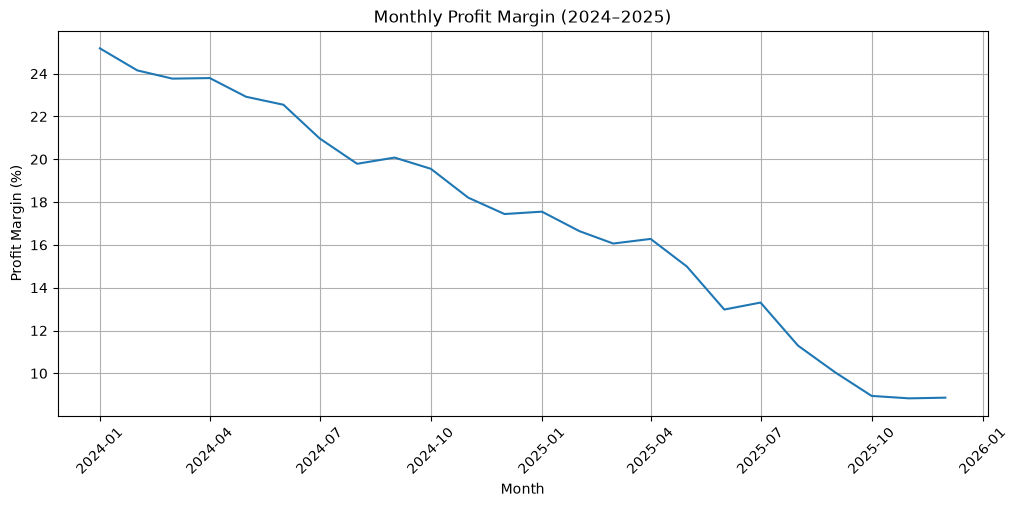

In [43]:
#createing a simple chart showing monthly profit margin
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 5))
plt.plot(monthly_margin.index, monthly_margin.values)
plt.title("Monthly Profit Margin (2024–2025)")
plt.xlabel("Month")
plt.ylabel("Profit Margin (%)")
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

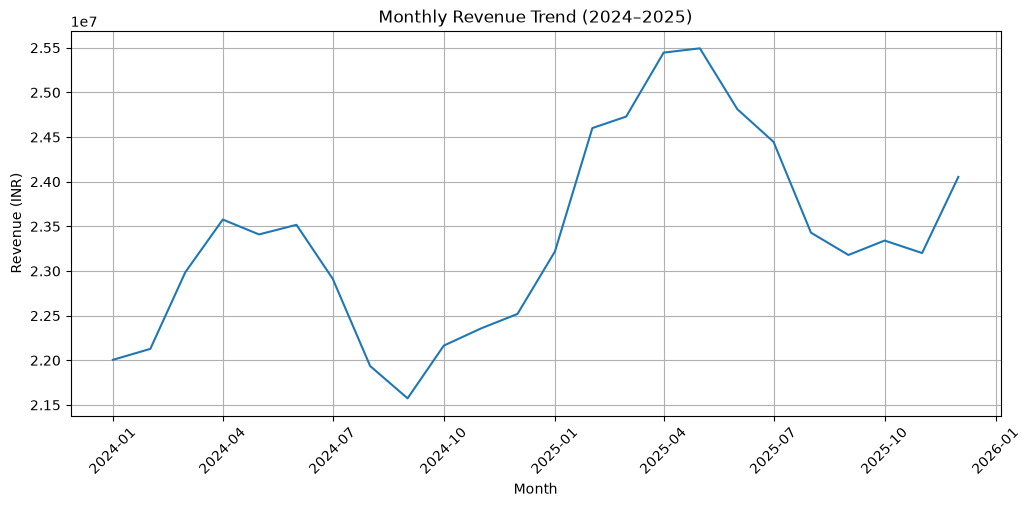

In [ ]:
#createing a line chart showing monthly revenue
plt.figure(figsize=(12, 5))
plt.plot(monthly_revenue.index, monthly_revenue.values)
plt.title("Monthly Revenue Trend (2024–2025)")
plt.xlabel("Month")
plt.ylabel("Revenue (INR)")
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

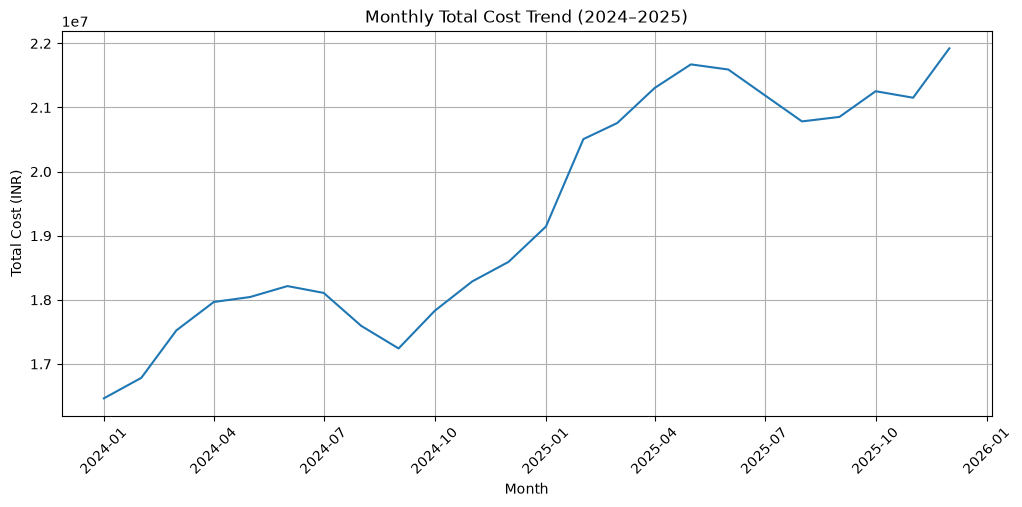

In [46]:
#Monthly total cost trend
monthly_cost = df.groupby("Month")["Total_Cost_INR"].sum()
plt.figure(figsize=(12, 5))
plt.plot(monthly_cost.index, monthly_cost.values)
plt.title("Monthly Total Cost Trend (2024–2025)")
plt.xlabel("Month")
plt.ylabel("Total Cost (INR)")
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

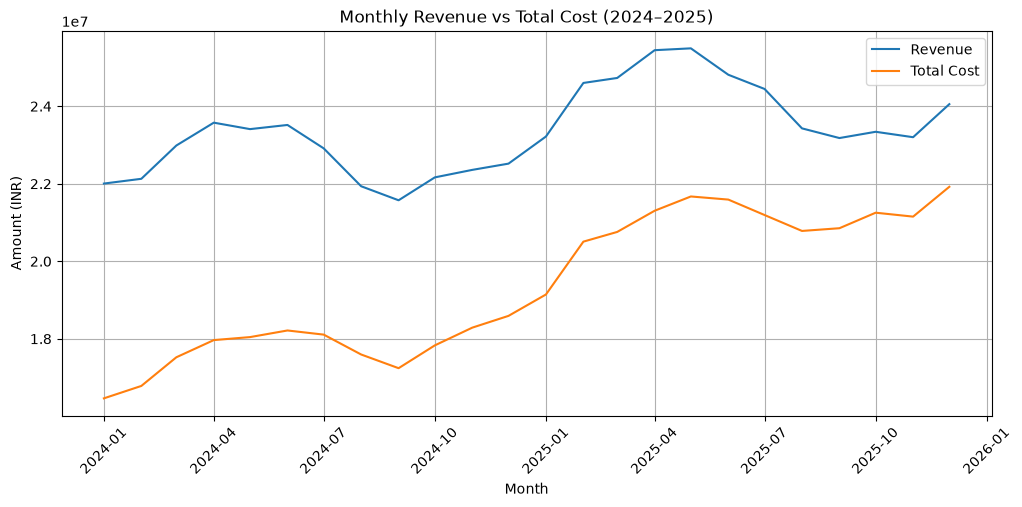

In [47]:
# Compareing monthly revenue and total costs
plt.figure(figsize=(12, 5))
plt.plot(monthly_revenue.index, monthly_revenue.values, label="Revenue")
plt.plot(monthly_cost.index, monthly_cost.values, label="Total Cost")
plt.title("Monthly Revenue vs Total Cost (2024–2025)")
plt.xlabel("Month")
plt.ylabel("Amount (INR)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.show()

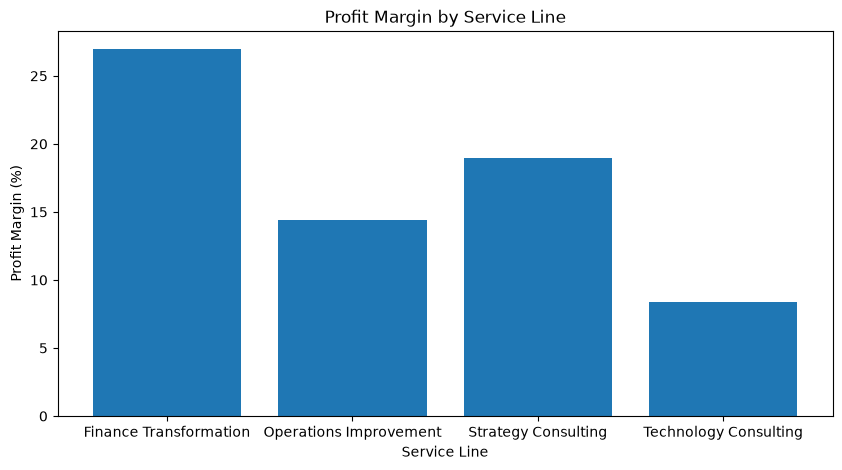

In [49]:
# Calculating profit margin by service line
service_profit = df.groupby("Service_Line")["Profit_INR"].sum()
service_revenue = df.groupby("Service_Line")["Revenue_INR"].sum()
service_margin = (service_profit / service_revenue) * 100
plt.figure(figsize=(10, 5))
plt.bar(service_margin.index, service_margin.values)
plt.title("Profit Margin by Service Line")
plt.xlabel("Service Line")
plt.ylabel("Profit Margin (%)")
plt.show()

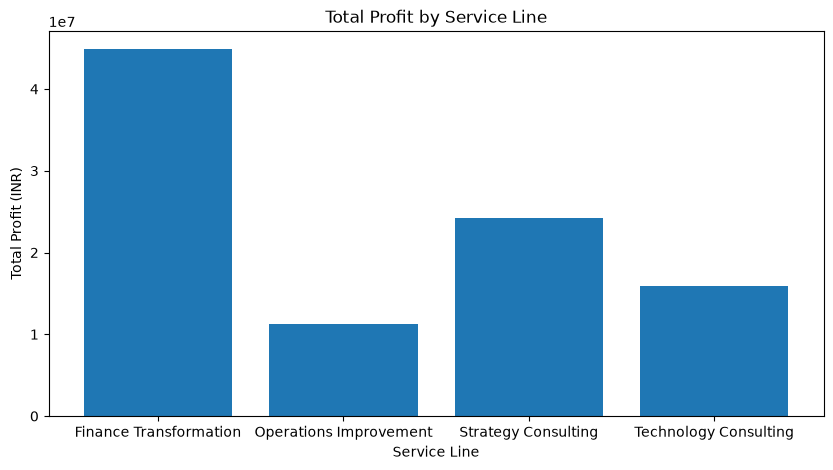

In [51]:
#Profit by service line
plt.figure(figsize=(10, 5))
plt.bar(service_profit.index, service_profit.values)
plt.title("Total Profit by Service Line")
plt.xlabel("Service Line")
plt.ylabel("Total Profit (INR)")
plt.show()

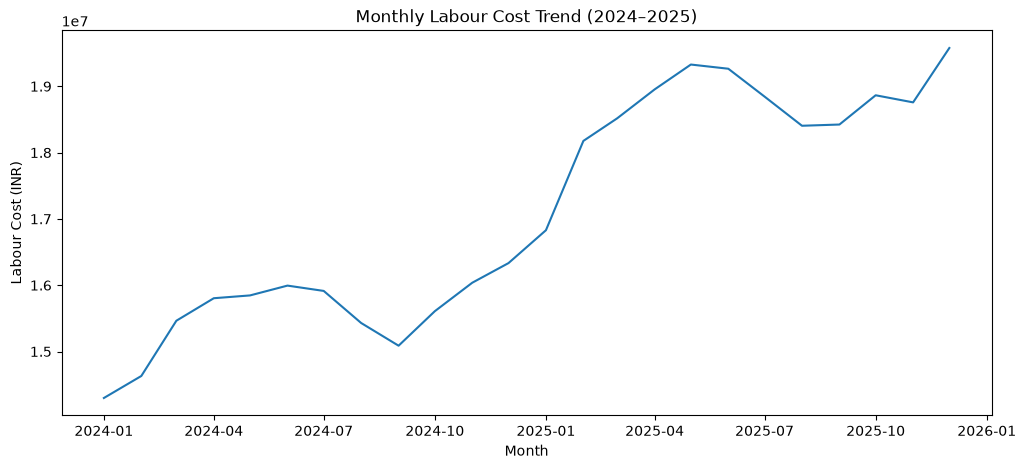

In [ ]:
# Monthly labour cost
monthly_labor = df.groupby("Month")["Labor_Cost_INR"].sum()
plt.figure(figsize=(12, 5))
plt.plot(monthly_labor.index, monthly_labor.values)
plt.title("Monthly Labour Cost Trend (2024–2025)")
plt.xlabel("Month")
plt.ylabel("Labour Cost (INR)")
plt.show()

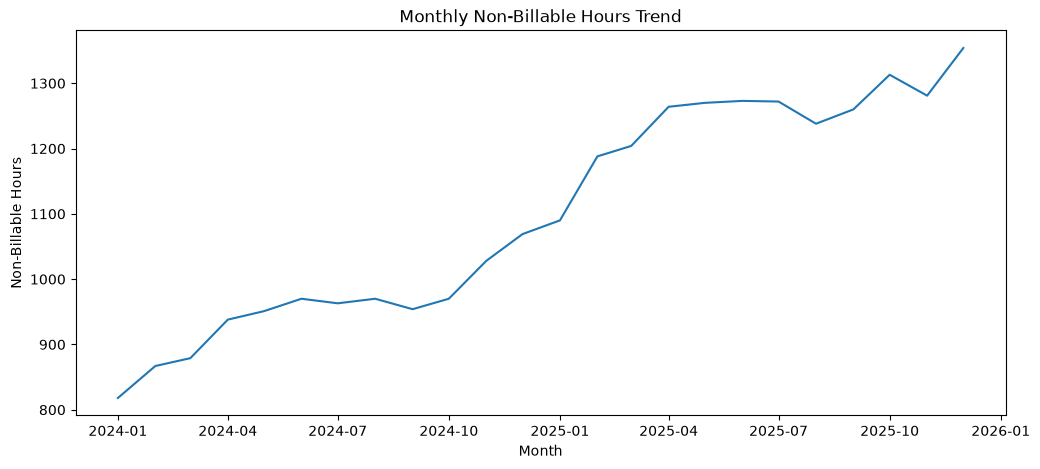

In [58]:
#Analyzing non-billable hours
monthly_non_billable = df.groupby("Month")["Non_Billable_Hours"].sum()
plt.figure(figsize=(12, 5))
plt.plot(monthly_non_billable.index, monthly_non_billable.values)
plt.title("Monthly Non-Billable Hours Trend")
plt.xlabel("Month")
plt.ylabel("Non-Billable Hours")
plt.show()

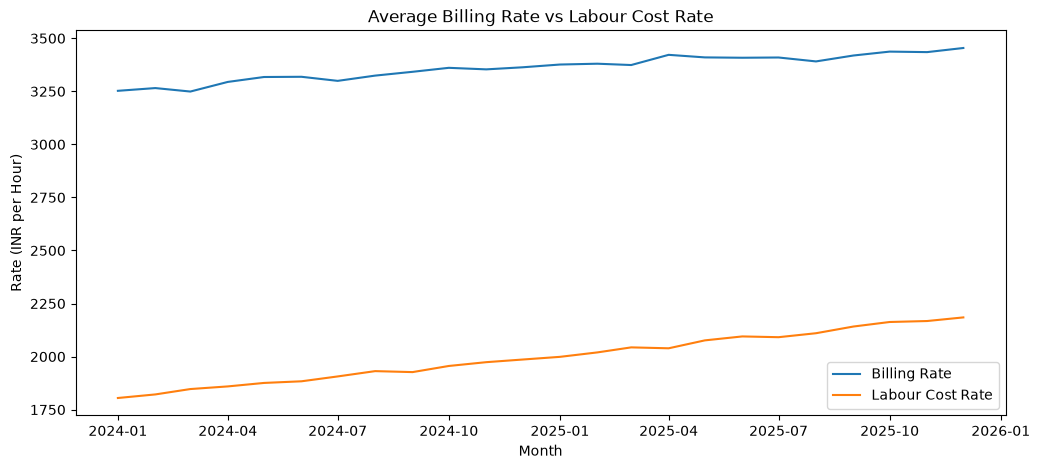

In [ ]:
#Is company increasing its employee costs faster than its client billing rates
monthly_billing_rate = df.groupby("Month")["Billing_Rate_INR_per_Hour"].mean()
monthly_labor_rate = df.groupby("Month")["Labor_Cost_Rate_INR_per_Hour"].mean()
plt.figure(figsize=(12, 5))
plt.plot(monthly_billing_rate.index, monthly_billing_rate.values, label="Billing Rate")
plt.plot(monthly_labor_rate.index, monthly_labor_rate.values, label="Labour Cost Rate")
plt.title("Average Billing Rate vs Labour Cost Rate")
plt.xlabel("Month")
plt.ylabel("Rate (INR per Hour)")
plt.legend()
plt.show()

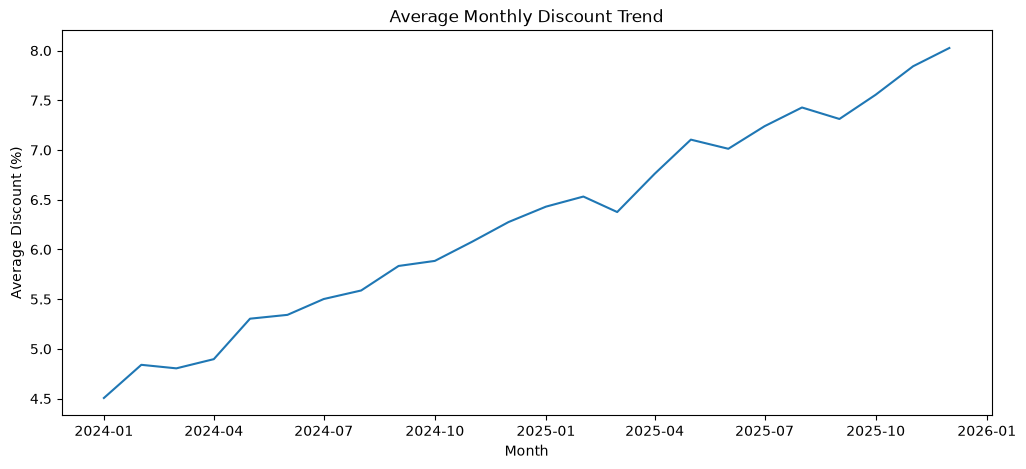

In [61]:
#checking whether the company is also giving larger discounts to clients 
monthly_discount = df.groupby("Month")["Discount_Pct"].mean() * 100
plt.figure(figsize=(12, 5))
plt.plot(monthly_discount.index, monthly_discount.values)
plt.title("Average Monthly Discount Trend")
plt.xlabel("Month")
plt.ylabel("Average Discount (%)")
plt.show()

In [63]:
#Which engagements are consistently loss-making?
engagement_profit = df.groupby("Engagement_ID")["Profit_INR"].sum()
engagement_profit.sort_values()

Engagement_ID
ENG-034   -3.981353e+06
ENG-008   -3.920143e+06
ENG-038   -3.058250e+06
ENG-056   -2.930648e+06
ENG-046   -2.882964e+06
ENG-026   -2.798326e+06
ENG-054   -2.603593e+06
ENG-016   -2.244017e+06
ENG-020   -2.129462e+06
ENG-023   -2.056819e+06
ENG-060   -1.911068e+06
ENG-001   -1.777847e+06
ENG-053   -1.633876e+06
ENG-044   -1.263320e+06
ENG-055   -8.988341e+05
ENG-012   -8.172530e+05
ENG-018   -5.342813e+05
ENG-039   -4.022236e+05
ENG-049   -3.632477e+05
ENG-010   -2.056530e+05
ENG-042   -7.871622e+04
ENG-040    4.554390e+04
ENG-021    1.112532e+05
ENG-032    3.267687e+05
ENG-013    3.893792e+05
ENG-009    3.920390e+05
ENG-004    7.203549e+05
ENG-015    7.779738e+05
ENG-036    9.255082e+05
ENG-029    9.412272e+05
ENG-043    1.065470e+06
ENG-045    1.218372e+06
ENG-052    1.219233e+06
ENG-025    1.325649e+06
ENG-017    1.453919e+06
ENG-035    1.754619e+06
ENG-037    2.418932e+06
ENG-028    2.450470e+06
ENG-047    2.555160e+06
ENG-002    2.566395e+06
ENG-019    3.554874e+06
EN

In [64]:
loss_engagements = ["ENG-034", "ENG-008", "ENG-038", "ENG-056", "ENG-046"]
df[df["Engagement_ID"].isin(loss_engagements)][["Engagement_ID", "Service_Line"]].drop_duplicates()

,Engagement_ID,Service_Line
7,ENG-008,Technology Consulting
33,ENG-034,Technology Consulting
37,ENG-038,Technology Consulting
45,ENG-046,Finance Transformation
55,ENG-056,Strategy Consulting


In [69]:
df[df["Engagement_ID"] == "ENG-034"][[ 
    "Month",
    "Revenue_INR",
    "Labor_Cost_INR",
    "Total_Cost_INR",
    "Profit_INR",
    "Profit_Margin_Pct"
]]

,Month,Revenue_INR,Labor_Cost_INR,Total_Cost_INR,Profit_INR,Profit_Margin_Pct
33,2024-01-01,328161.613600,394155.37,445904.80,-117743.186400,-0.358796
93,2024-02-01,316239.973833,401126.40,434438.70,-118198.726167,-0.373763
153,2024-03-01,340906.191360,413788.32,452502.27,-111596.078640,-0.327351
213,2024-04-01,346900.956180,439969.25,486437.18,-139536.223820,-0.402236
273,2024-05-01,291991.197960,375398.96,409758.63,-117767.432040,-0.403325
333,2024-06-01,312564.749554,411601.33,441736.35,-129171.600446,-0.413263
393,2024-07-01,344473.363260,462992.25,503393.28,-158919.916740,-0.461342
453,2024-08-01,269896.009229,366401.75,407048.08,-137152.070771,-0.508166
513,2024-09-01,308832.837568,408732.80,436700.02,-127867.182432,-0.414034
573,2024-10-01,286660.262304,363314.70,390265.24,-103604.977696,-0.361421


In [70]:
#Profit by client
client_profit = df.groupby("Client_ID")["Profit_INR"].sum()
client_profit.sort_values().head(10)

Client_ID
CL-034   -3.981353e+06
CL-012   -3.420846e+06
CL-038   -3.058250e+06
CL-026   -2.798326e+06
CL-018   -2.445350e+06
CL-004   -2.162609e+06
CL-020   -2.129462e+06
CL-023   -2.056819e+06
CL-001   -7.123774e+05
CL-013   -5.094549e+05
Name: Profit_INR, dtype: float64

In [71]:
#which cost category contributes the most to the companys total costs
df[[
    "Labor_Cost_INR",
    "Subcontractor_Cost_INR",
    "Travel_Cost_INR",
    "Other_Direct_Cost_INR"
]].sum()

Labor_Cost_INR            4.103898e+08
Subcontractor_Cost_INR    3.052101e+07
Travel_Cost_INR           1.540594e+07
Other_Direct_Cost_INR     8.467800e+06
dtype: float64

In [72]:
#calculating the percentage contribution of each cost category
cost_data = df[[
    "Labor_Cost_INR",
    "Subcontractor_Cost_INR",
    "Travel_Cost_INR",
    "Other_Direct_Cost_INR"
]].sum()
cost_percentage = (cost_data / cost_data.sum()) * 100
cost_percentage

Labor_Cost_INR            88.296782
Subcontractor_Cost_INR     6.566701
Travel_Cost_INR            3.314641
Other_Direct_Cost_INR      1.821877
dtype: float64

In [73]:
#determining whether the increase is primarily due to employees working more hours, higher employee costs per hour, or both
monthly_labor_analysis = df.groupby("Month").agg({
    "Billable_Hours": "sum",
    "Non_Billable_Hours": "sum",
    "Labor_Cost_INR": "sum"
})
monthly_labor_analysis["Total_Hours"] = (
    monthly_labor_analysis["Billable_Hours"] +
    monthly_labor_analysis["Non_Billable_Hours"]
)
monthly_labor_analysis["Average_Labor_Cost_Per_Hour"] = (
    monthly_labor_analysis["Labor_Cost_INR"] /
    monthly_labor_analysis["Total_Hours"]
)
monthly_labor_analysis.loc[
    ["2024-01-01", "2025-12-01"]
]

,Billable_Hours,Non_Billable_Hours,Labor_Cost_INR,Total_Hours,Average_Labor_Cost_Per_Hour
Month,,,,,
2024-01-01,7067,818,14298727.04,7885,1813.408629
2025-12-01,7550,1354,19577809.37,8904,2198.765653


In [74]:
#calculating how much of the total working time is billable
monthly_labor_analysis["Billable_Utilization_Pct"] = (
    monthly_labor_analysis["Billable_Hours"] /
    monthly_labor_analysis["Total_Hours"]
) * 100
monthly_labor_analysis[["Billable_Utilization_Pct"]].loc[
    ["2024-01-01", "2025-12-01"]
]

,Billable_Utilization_Pct
Month,
2024-01-01,89.625872
2025-12-01,84.793351


In [75]:
#calculating how much gross billing is being reduced by discounts across the entire data
total_gross_billings = df["Gross_Billings_INR"].sum()
total_revenue = df["Revenue_INR"].sum()
discount_impact = total_gross_billings - total_revenue
print("Total Gross Billings:", total_gross_billings)
print("Total Revenue:", total_revenue)
print("Revenue Lost Due to Discounts:", discount_impact)

Total Gross Billings: 598539392.12
Total Revenue: 561040236.925007
Revenue Lost Due to Discounts: 37499155.19499302


In [83]:
# Final Project Summary
summary = pd.DataFrame({
    "KPI": [
        "Total Revenue",
        "Total Profit",
        "Overall Profit Margin",
        "Jan 2024 Profit Margin",
        "Dec 2025 Profit Margin"
    ],
    "Finding": [
        "₹56.10 Cr",
        "₹9.63 Cr",
        "17.16%",
        "25.18%",
        "8.86%"
    ]
})

print("OVERALL BUSINESS PERFORMANCE")
display(summary)

# Business Findings
findings = pd.DataFrame({
    "Finding": [
        "Labour Costs Increased",
        "Non-billable Hours Increased",
        "Labour Cost per Hour Increased",
        "Billable Utilisation Declined",
        "Revenue Reduction Through Discounts",
        "Lowest-Margin Service Line"
    ],
    "Evidence": [
        "+36.9%",
        "+65.5%",
        "+21.3%",
        "89.63% to 84.79%",
        "₹3.75 Cr",
        "Technology Consulting: 8.42%"
    ]
})

print("MAJOR BUSINESS FINDINGS")
display(findings)

# Conclusion
print("PROJECT CONCLUSION")
print(
    "Profit margin declined by 16.32 percentage points, "
    "despite revenue increasing by approximately 9.3%."
)

OVERALL BUSINESS PERFORMANCE


,KPI,Finding
0,Total Revenue,₹56.10 Cr
1,Total Profit,₹9.63 Cr
2,Overall Profit Margin,17.16%
3,Jan 2024 Profit Margin,25.18%
4,Dec 2025 Profit Margin,8.86%


MAJOR BUSINESS FINDINGS


,Finding,Evidence
0,Labour Costs Increased,+36.9%
1,Non-billable Hours Increased,+65.5%
2,Labour Cost per Hour Increased,+21.3%
3,Billable Utilisation Declined,89.63% to 84.79%
4,Revenue Reduction Through Discounts,₹3.75 Cr
5,Lowest-Margin Service Line,Technology Consulting: 8.42%


PROJECT CONCLUSION
Profit margin declined by 16.32 percentage points, despite revenue increasing by approximately 9.3%.
